# Sprint 8 - Proyecto

## Introducción

En este proyecto se analizarán datos relacionados con los viajes en taxi realizados en Chicago durante noviembre de 2017.

El análisis se enfocará en identificar las compañías de taxis con mayor número de viajes y los barrios en los que se registraron más finalizaciones de recorridos. Para ello, se realizará una exploración de los datos, se comprobará su calidad y se crearán visualizaciones que permitan interpretar los principales patrones encontrados.

Posteriormente, se analizarán los viajes realizados desde el barrio Loop hasta el Aeropuerto Internacional O'Hare para determinar si las condiciones meteorológicas están asociadas con cambios en la duración promedio de los viajes durante los sábados.

El proyecto se dividirá en dos partes principales:

* Análisis exploratorio de datos.
* Prueba de hipótesis sobre la duración de los viajes en distintas condiciones meteorológicas.


## 1. Preparación y revisión inicial de los datos

Primero se importarán las librerías necesarias y se cargarán los datasets utilizados para el análisis exploratorio.

Después se realizará una revisión inicial de cada conjunto de datos para conocer su estructura, identificar los tipos de datos de las columnas y detectar posibles valores ausentes o registros duplicados.

Esta revisión permitirá determinar si es necesario realizar alguna transformación o limpieza antes de comenzar el análisis.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Cargamos los archivos necesarios para realizar el análisis.

In [2]:
company_data = pd.read_csv('datasets/project_sql_result_01.csv')
neighborhood_data = pd.read_csv('datasets/project_sql_result_04.csv')

Revisamos los datos contenidos en los archivos. Empezamos con el archivo que contiene la información de las compañías, `company_data`.

In [3]:
company_data.head()

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [4]:
company_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   company_name  64 non-null     str  
 1   trips_amount  64 non-null     int64
dtypes: int64(1), str(1)
memory usage: 2.5 KB


La tabla contiene 64 registros y dos columnas. La columna company_name tiene tipo object, adecuado para almacenar los nombres de las compañías, mientras que trips_amount tiene tipo int64, apropiado para representar el número de viajes. Por lo tanto, los tipos de datos son correctos y no requieren conversión. Además, ambas columnas contienen 64 valores no nulos, por lo que no se observan datos ausentes.

A continuación, comprobaremos si existen registros duplicados.

In [5]:
company_data.duplicated().sum()

np.int64(0)

No se encontraron registros duplicados en `company_data`.

Podemos continuar con el mismo análisis para el archivo `neighborhood_data`.

In [6]:
neighborhood_data.head()

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


In [7]:
neighborhood_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     str    
 1   average_trips          94 non-null     float64
dtypes: float64(1), str(1)
memory usage: 2.6 KB


La tabla `neighborhood_data` contiene 94 registros y dos columnas. La columna `dropoff_location_name` tiene tipo `object`, adecuado para almacenar los nombres de los barrios, mientras que `average_trips` tiene tipo `float64`, apropiado para representar el promedio de viajes. Por lo tanto, los tipos de datos son correctos y no requieren conversión.

Además, ambas columnas contienen 94 valores no nulos, por lo que no se observan datos ausentes.

A continuación, comprobaremos si existen registros duplicados.

In [8]:
neighborhood_data.duplicated().sum()

np.int64(0)

No se encontraron registros duplicados en `neighborhood_data`.

## 2. Análisis exploratorio de los datos

Comenzamos identificando los 10 barrios con el mayor promedio de viajes finalizados durante noviembre de 2017.

In [9]:
top_10_neighborhoods = neighborhood_data.sort_values(
    by='average_trips',
    ascending=False
).head(10)

top_10_neighborhoods

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


A continuación, representamos gráficamente los 10 barrios con mayor promedio de viajes finalizados para facilitar la comparación entre ellos.

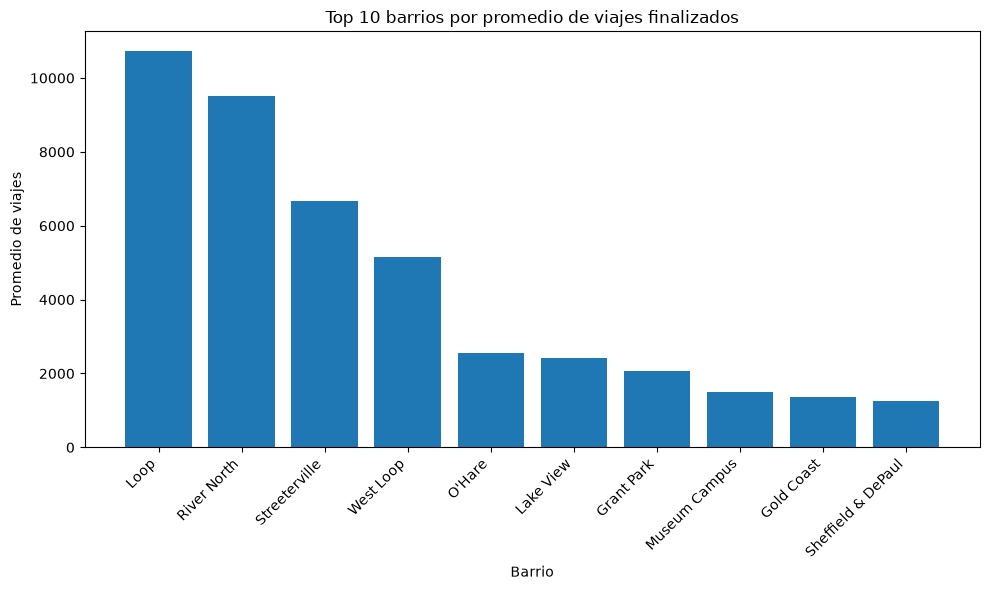

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_10_neighborhoods['dropoff_location_name'],
    top_10_neighborhoods['average_trips']
)

plt.title('Top 10 barrios por promedio de viajes finalizados')
plt.xlabel('Barrio')
plt.ylabel('Promedio de viajes')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Conclusión

El Loop presenta el mayor promedio de viajes finalizados, con más de 10,000 viajes, seguido por River North con aproximadamente 9,500. Después de estos dos barrios se observa una disminución importante, aunque Streeterville y West Loop también destacan entre los principales destinos.

A partir de O'Hare, el promedio de viajes es considerablemente menor. En conjunto, los resultados muestran que las finalizaciones de viajes se concentran principalmente en unos cuantos barrios, especialmente en Loop y River North.

### Empresas de taxis y número de viajes

A continuación, analizamos el número de viajes realizados por cada compañía de taxis para identificar cuáles presentan una mayor actividad.

Para complementar la visualización y observar con mayor precisión los valores, mostramos las 10 compañías con el mayor número de viajes.

In [11]:
top_10_companies = company_data.sort_values(
    by='trips_amount',
    ascending=False
).head(10)

top_10_companies

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299
5,Chicago Carriage Cab Corp,9181
6,City Service,8448
7,Sun Taxi,7701
8,Star North Management LLC,7455
9,Blue Ribbon Taxi Association Inc.,5953


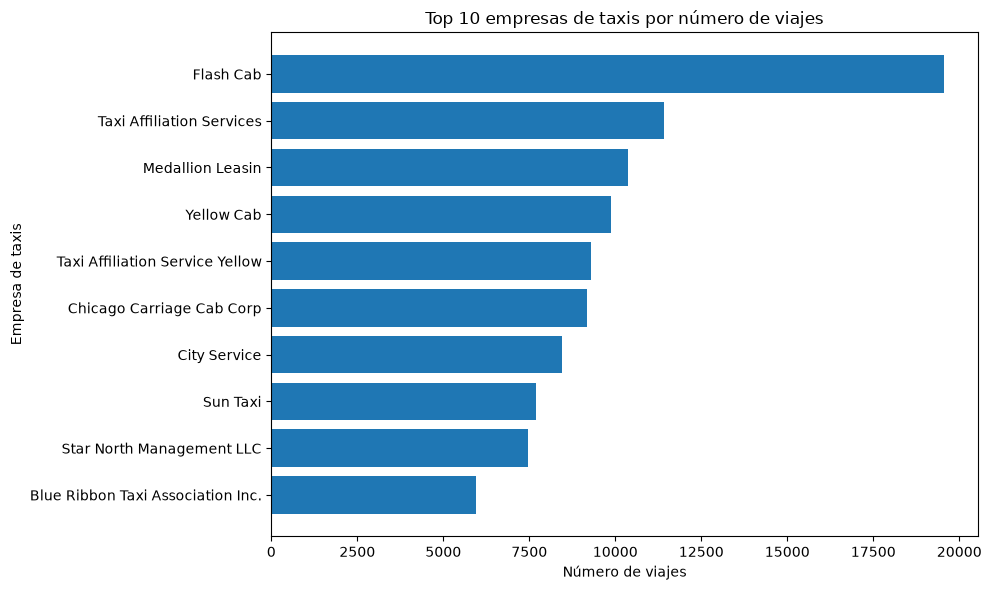

In [12]:
top_10_companies_sorted = top_10_companies.sort_values(
    by='trips_amount',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_companies_sorted['company_name'],
    top_10_companies_sorted['trips_amount']
)

plt.title('Top 10 empresas de taxis por número de viajes')
plt.xlabel('Número de viajes')
plt.ylabel('Empresa de taxis')

plt.tight_layout()
plt.show()

### Conclusión

Flash Cab es la compañía con el mayor número de viajes, con 19,558, seguida por Taxi Affiliation Services con 11,422. La diferencia entre ambas es considerable.

TTambién destacan Medallion Leasing, Yellow Cab y Taxi Affiliation Service Yellow, con 10,367, 9,888 y 9,299 viajes, respectivamente. Dentro de las 10 compañías con mayor número de viajes se observa una disminución progresiva después de las primeras posiciones.

En conjunto, se observa que unas pocas compañías registran una cantidad de viajes mucho mayor que el resto durante el periodo analizado.

## 3. Prueba de hipótesis

En esta sección analizaremos los viajes realizados los sábados desde el Loop hasta el Aeropuerto Internacional O'Hare para determinar si la duración promedio de los viajes cambia dependiendo de las condiciones meteorológicas.

Primero cargaremos el dataset que contiene la fecha y hora de inicio del viaje, las condiciones climáticas y la duración del recorrido.

In [13]:
trips_weather_data = pd.read_csv('datasets/project_sql_result_07.csv')

Posteriormente revisamos los datos contenidos en el archivo.

In [14]:
trips_weather_data.head()

,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


In [15]:
trips_weather_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   str    
 1   weather_conditions  1068 non-null   str    
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), str(2)
memory usage: 49.0 KB


La tabla contiene 1,068 registros y tres columnas. No se observan valores ausentes, ya que las tres columnas contienen 1,068 valores no nulos.

La columna `weather_conditions` tiene tipo `object`, adecuado para almacenar las categorías de condiciones meteorológicas, y `duration_seconds` tiene tipo `float64`, apropiado para representar la duración de los viajes.

Sin embargo, `start_ts` aparece como tipo `object`. Debido a que contiene información de fecha y hora, convertiremos esta columna al tipo `datetime` antes de continuar con el análisis.

In [16]:
trips_weather_data['start_ts'] = pd.to_datetime(
    trips_weather_data['start_ts']
)

trips_weather_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[us]
 1   weather_conditions  1068 non-null   str           
 2   duration_seconds    1068 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 29.2 KB


La columna `start_ts` se convirtió correctamente al tipo `datetime`, por lo que los tipos de datos del conjunto son ahora adecuados para el análisis.

Antes de realizar la prueba de hipótesis, comprobaremos si existen registros duplicados en el dataset.

In [17]:
trips_weather_data.duplicated().sum()

np.int64(197)

Se identificaron 197 filas con valores repetidos en todas las columnas disponibles. Sin embargo, el dataset no incluye un identificador único del viaje, como `trip_id`, por lo que no es posible determinar que estas filas correspondan realmente al mismo viaje.

Es posible que distintos viajes hayan comenzado a la misma hora, bajo las mismas condiciones meteorológicas y con la misma duración. Por esta razón, no eliminaremos estos registros para evitar descartar observaciones válidas y alterar la muestra utilizada en la prueba de hipótesis.

También revisamos si existen valores de duración iguales o menores que cero, ya que no representarían una duración válida para un viaje desde el Loop hasta el Aeropuerto Internacional O'Hare.

In [18]:
trips_weather_data[
    trips_weather_data['duration_seconds'] <= 0
].shape[0]

6

In [19]:
trips_weather_data[
    trips_weather_data['duration_seconds'] <= 0
]

,start_ts,weather_conditions,duration_seconds
163,2017-11-11 09:00:00,Good,0.0
168,2017-11-11 07:00:00,Good,0.0
204,2017-11-18 19:00:00,Good,0.0
552,2017-11-04 01:00:00,Good,0.0
801,2017-11-04 09:00:00,Good,0.0
1063,2017-11-25 11:00:00,Good,0.0


Se encontraron 6 registros con una duración de 0 segundos y no se observaron duraciones negativas. Todos estos registros corresponden a condiciones meteorológicas `Good`.

Una duración de 0 segundos no representa un viaje válido desde el Loop hasta el Aeropuerto Internacional O'Hare, por lo que estos registros se consideran valores inválidos y serán eliminados antes de realizar el análisis estadístico.

In [20]:
trips_weather_data = trips_weather_data[
    trips_weather_data['duration_seconds'] > 0
].copy()

trips_weather_data.shape

(1062, 3)

Después de eliminar los 6 registros con duración igual a 0 segundos, el dataset contiene 1,062 viajes válidos para el análisis estadístico.

Revisemos cuántos viajes hay en cada categoría de clima.

In [21]:
trips_weather_data['weather_conditions'].value_counts()

weather_conditions
Good    882
Bad     180
Name: count, dtype: int64

Después de la limpieza, contamos con 882 viajes realizados bajo condiciones meteorológicas `Good` y 180 bajo condiciones `Bad`. Ambos grupos contienen suficientes observaciones para realizar la comparación estadística.

### Formulación de las hipótesis

Para evaluar si las condiciones meteorológicas están asociadas con un cambio en la duración promedio de los viajes, planteamos las siguientes hipótesis:

- **Hipótesis nula (H₀):** la duración promedio de los viajes es igual bajo condiciones meteorológicas `Good` y `Bad`.
- **Hipótesis alternativa (H₁):** la duración promedio de los viajes es diferente bajo condiciones meteorológicas `Good` y `Bad`.

Utilizaremos un nivel de significación de **α = 0.05**.

La hipótesis alternativa es bilateral porque queremos determinar si la duración promedio cambia, sin asumir previamente que aumentará o disminuirá bajo malas condiciones meteorológicas.

Separemos la duración de los viajes en las dos muestras que vamos a comparar.

In [22]:
good_weather_trips = trips_weather_data[
    trips_weather_data['weather_conditions'] == 'Good'
]['duration_seconds']

bad_weather_trips = trips_weather_data[
    trips_weather_data['weather_conditions'] == 'Bad'
]['duration_seconds']

Antes de realizar la prueba de hipótesis, comparamos algunas estadísticas descriptivas de ambos grupos. Esto nos permitirá observar el tamaño de cada muestra, la duración promedio de los viajes y la variabilidad de los datos bajo condiciones meteorológicas `Good` y `Bad`.

In [23]:
comparison_stats = pd.DataFrame({
    'Good': [
        good_weather_trips.count(),
        good_weather_trips.mean(),
        good_weather_trips.var()
    ],
    'Bad': [
        bad_weather_trips.count(),
        bad_weather_trips.mean(),
        bad_weather_trips.var()
    ]
}, index=['count', 'mean_duration', 'variance'])

comparison_stats

,Good,Bad
count,882.000000,180.000000
mean_duration,2013.278912,2427.205556
variance,552889.231995,520294.086002


Los viajes realizados con condiciones meteorológicas `Good` tienen una duración promedio aproximada de 2,013 segundos, mientras que bajo condiciones `Bad` el promedio es de aproximadamente 2,427 segundos. Esto representa una diferencia observable de alrededor de 414 segundos, es decir, poco menos de 7 minutos.

Las varianzas de ambos grupos son del mismo orden de magnitud, aunque no son exactamente iguales. Además, los tamaños de las muestras son considerablemente diferentes: 882 observaciones para `Good` y 180 para `Bad`.

Estas diferencias descriptivas no son suficientes por sí solas para determinar si la diferencia entre las duraciones promedio es estadísticamente significativa. Antes de realizar la prueba t, comprobaremos si podemos asumir igualdad de varianzas entre ambos grupos.

### Comprobación de la homogeneidad de varianzas

Para comprobar formalmente si podemos asumir igualdad de varianzas en la prueba t, aplicaremos la prueba de Levene.

En esta prueba:

- **H₀:** las varianzas de los grupos `Good` y `Bad` son iguales.
- **H₁:** las varianzas de los grupos `Good` y `Bad` son diferentes.

Utilizaremos un nivel de significación de α = 0.05. El resultado determinará qué valor utilizaremos para el parámetro `equal_var` en la prueba t.

In [24]:
from scipy import stats

alpha = 0.05

levene_result = stats.levene(
    good_weather_trips,
    bad_weather_trips
)

print('p-value de Levene:', levene_result.pvalue)

p-value de Levene: 0.6687312920630736


El valor p obtenido en la prueba de Levene es aproximadamente 0.669, mayor que el nivel de significación de α = 0.05.

Por lo tanto, no rechazamos la hipótesis nula de igualdad de varianzas. No existe evidencia estadística suficiente para afirmar que las varianzas de los grupos `Good` y `Bad` sean diferentes.

Con base en este resultado, utilizaremos `equal_var=True` en la prueba t para dos muestras independientes.

### Prueba estadística

Para contrastar las hipótesis utilizaremos una prueba t para dos muestras independientes, ya que queremos comparar la duración promedio de dos grupos distintos de viajes: aquellos realizados bajo condiciones meteorológicas `Good` y aquellos realizados bajo condiciones `Bad`.

La prueba de Levene obtuvo un valor p mayor que el nivel de significación de α = 0.05, por lo que no encontramos evidencia estadística suficiente para afirmar que las varianzas de ambos grupos sean diferentes. Por esta razón, utilizaremos `equal_var=True` en la prueba t.

Compararemos el valor p obtenido con el nivel de significación α = 0.05:

- Si el valor p es menor que α, rechazaremos la hipótesis nula.
- Si el valor p es mayor o igual que α, no tendremos evidencia suficiente para rechazar la hipótesis nula.

In [25]:
alpha = 0.05

results = stats.ttest_ind(
    good_weather_trips,
    bad_weather_trips,
    equal_var=True
)

print('p-value:', results.pvalue)

p-value: 1.3318772977743224e-11


### Resultado de la prueba de hipótesis

El valor p obtenido es aproximadamente `1.33 × 10⁻¹¹`, considerablemente menor que el nivel de significación establecido de α = 0.05.

Por lo tanto, rechazamos la hipótesis nula. Existe evidencia estadísticamente significativa para concluir que la duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare es diferente entre los sábados con condiciones meteorológicas `Good` y los sábados con condiciones meteorológicas `Bad`.

Además, en el análisis descriptivo observamos que los viajes bajo condiciones `Bad` tuvieron una duración promedio de aproximadamente 2,427 segundos, frente a aproximadamente 2,013 segundos bajo condiciones `Good`, una diferencia cercana a 414 segundos (aproximadamente 6.9 minutos).

Estos resultados muestran una asociación entre las condiciones meteorológicas adversas y la duración de los viajes analizados, aunque la prueba estadística por sí sola no permite establecer una relación causal.

## 4. Conclusión general

El análisis permitió identificar patrones claros tanto en la distribución de los viajes como en su duración bajo distintas condiciones meteorológicas.

En cuanto a los destinos, el Loop presentó el mayor promedio de viajes finalizados, seguido por River North. Ambos barrios se encuentran claramente por encima del resto, lo que muestra una concentración importante de viajes en estas zonas. Después aparecen Streeterville y West Loop, mientras que a partir de O'Hare el promedio de viajes disminuye considerablemente.

Respecto a las compañías de taxis, Flash Cab registró el mayor número de viajes, con 19,558, seguida por Taxi Affiliation Services con 11,422. También destacaron Medallion Leasing, Yellow Cab y Taxi Affiliation Service Yellow. La distribución muestra que un grupo relativamente pequeño de compañías concentra una parte importante de los viajes, mientras que muchas otras presentan volúmenes considerablemente menores.

Finalmente, la prueba de hipótesis mostró una diferencia estadísticamente significativa entre la duración promedio de los viajes realizados bajo condiciones meteorológicas `Good` y `Bad`. Los viajes con condiciones `Bad` tuvieron una duración promedio aproximada de 2,427 segundos, frente a aproximadamente 2,013 segundos bajo condiciones `Good`, una diferencia de aproximadamente 414 segundos.

Dado que el valor p obtenido fue muy inferior al nivel de significación de 0.05, se rechazó la hipótesis nula. Por lo tanto, existe evidencia estadística de que la duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare es diferente entre los sábados con condiciones meteorológicas `Good` y los sábados con condiciones meteorológicas `Bad`. Los resultados muestran una asociación entre el clima y la duración de los viajes, aunque este análisis no permite establecer por sí solo una relación causal.